# Surface EMG-Based Hand Gesture Recognition
**Farzan Aghaei · Sanaz Mazraeh**  
Department of Electrical Engineering, Sharif University of Technology  
Sensing and Measurements — Hand Gesture Classification

This notebook implements the complete analysis of a 12-channel surface EMG recording from NinaPro DB2 (Subject 14, Exercise 1). The workflow includes signal conditioning, segmentation, handcrafted feature extraction, supervised classification, and evaluation on held-out movement repetitions.

## 1. Experimental setup

The analysis uses `S14_E1_A1.mat`, sampled at **2,000 Hz**. The 17 non-rest movement labels in Exercise 1 form the classification targets. The exercise-specific file represents **one participant**; the reported evaluation therefore measures recognition of unseen repetitions from that participant, not generalization to other people.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, find_peaks, welch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'font.size': 10,
})

DATA_PATH = Path('data/S14_E1_A1.mat')
FS = 2000
BANDPASS = (20, 450)
WINDOW_MS = 200
STRIDE_MS = 100
TEST_REPETITIONS = (2, 5)
RANDOM_STATE = 42
assert DATA_PATH.exists(), (
    f'Missing input file: {DATA_PATH}. Place S14_E1_A1.mat in data/ before running.'
)

### 1.1 Recording metadata and labels

The MAT file contains 12 simultaneous EMG channels. The corrected `restimulus` and `rerepetition` annotations define the movement and repetition of each sample. Unlabeled/rest intervals (class 0) are excluded from the 17-class recognition task.

In [2]:
mat = loadmat(DATA_PATH, variable_names=['emg', 'restimulus', 'rerepetition'])
emg = np.asarray(mat['emg'], dtype=np.float64)
stimulus = np.asarray(mat['restimulus']).ravel().astype(int)
repetition = np.asarray(mat['rerepetition']).ravel().astype(int)

assert emg.ndim == 2 and emg.shape[1] == 12
assert emg.shape[0] == len(stimulus) == len(repetition)
assert np.isfinite(emg).all(), 'Input recording contains non-finite values.'
classes = np.unique(stimulus[stimulus > 0])
print(f'Recording length: {len(emg)/FS:.1f} s | Sampling frequency: {FS} Hz')
print(f'Channels: {emg.shape[1]} | Non-rest classes: {len(classes)}')
print(f'Movement IDs: {classes.tolist()}')
print(f'Repetition IDs: {np.unique(repetition[repetition>0]).tolist()}')

Recording length: 902.1 s | Sampling frequency: 2000 Hz
Channels: 12 | Non-rest classes: 17
Movement IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Repetition IDs: [1, 2, 3, 4, 5, 6]


## 2. Signal preprocessing

A **20–450 Hz Butterworth band-pass** (SciPy design order 4) is applied to each channel using forward–backward zero-phase filtering. The resulting waveform and power spectral density (PSD) are examined alongside the raw signal. No notch filter is applied in the reported experiment.

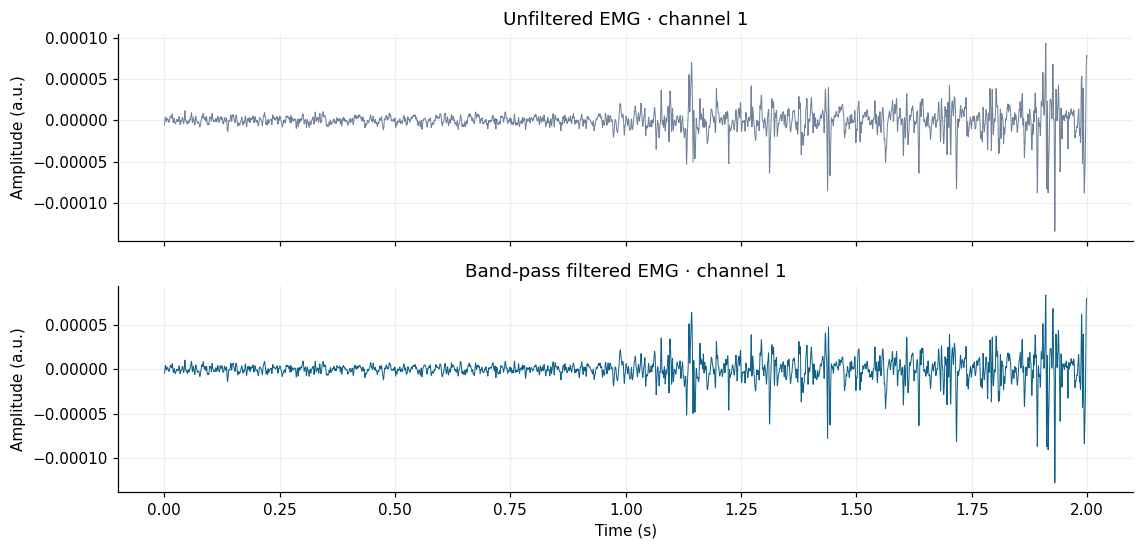

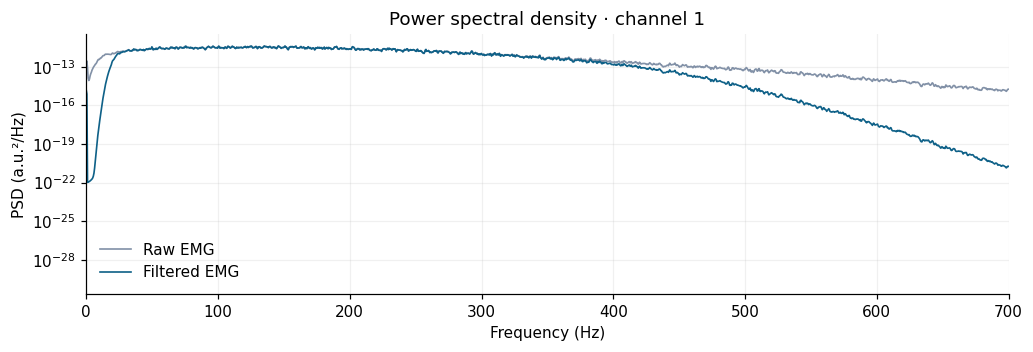

In [3]:
sos = butter(4, BANDPASS, btype='bandpass', fs=FS, output='sos')
emg_filtered = sosfiltfilt(sos, emg, axis=0)
assert np.isfinite(emg_filtered).all()

# Representative 2-s excerpt from the first active gesture.
active = np.flatnonzero((stimulus>0) & (repetition>0))
start = int(active[0]); length = 2 * FS
end = min(start + length, len(emg))
t = np.arange(end-start)/FS
fig, ax = plt.subplots(2, 1, figsize=(10.5, 5.1), sharex=True)
ax[0].plot(t, emg[start:end, 0], linewidth=.65, color='#71829A')
ax[0].set(title='Unfiltered EMG · channel 1', ylabel='Amplitude (a.u.)')
ax[1].plot(t, emg_filtered[start:end, 0], linewidth=.65, color='#0F6188')
ax[1].set(title='Band-pass filtered EMG · channel 1', xlabel='Time (s)', ylabel='Amplitude (a.u.)')
fig.tight_layout()
plt.show()

# Welch's PSD on the same recording, plotted in a comparable log scale.
f_raw, p_raw = welch(emg[:, 0], fs=FS, nperseg=4096)
f_filt, p_filt = welch(emg_filtered[:, 0], fs=FS, nperseg=4096)
fig, ax = plt.subplots(figsize=(9.5, 3.3))
ax.semilogy(f_raw, p_raw, label='Raw EMG', color='#8291A7', lw=1.1)
ax.semilogy(f_filt, p_filt, label='Filtered EMG', color='#0F6188', lw=1.1)
ax.set(xlim=(0, 700), xlabel='Frequency (Hz)', ylabel='PSD (a.u.²/Hz)', title='Power spectral density · channel 1')
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

## 3. Segmentation and feature extraction

The recording is segmented into **200 ms windows (400 samples)**, advanced every **100 ms (200 samples)**. A window is retained only if all samples belong to the same movement and repetition. Rest samples and unassigned repetitions are excluded.

For each channel, ten descriptors are calculated, producing a **120-dimensional vector per window**. Counts of zero crossings (ZC) and slope-sign changes (SSC) use small amplitude-dependent thresholds to suppress noise-sensitive events. For the inter-channel correlation, each channel is compared with the preceding channel (channel 1 uses a fixed zero placeholder).

| Descriptor | Measurement |
|---|---|
| MAV | Mean absolute amplitude |
| STD | Standard deviation |
| VAR | Signal variance |
| WL | Sum of absolute successive differences (waveform length) |
| ZC | Thresholded zero-crossing count |
| RMS | Root mean square amplitude |
| NP | Number of peaks in the rectified signal |
| SSC | Thresholded slope-sign change count |
| CORR | Pearson correlation with preceding EMG channel |
| IAV | Integrated absolute value over the window |

In [4]:
def extract_features(window: np.ndarray) -> np.ndarray:
    """Ten descriptors/channel; ZC and SSC count thresholded sign changes.

    MAV and IAV, and STD and VAR, carry partly redundant information but are
    included in the fixed 10-descriptor feature set.
    """
    descriptors = []
    for channel in range(window.shape[1]):
        x = window[:, channel]
        amplitude = np.std(x)
        epsilon = max(1e-10, amplitude * 0.01)
        dx = np.diff(x)
        crossings = np.sum((x[:-1] * x[1:] < 0) & (np.abs(x[:-1] - x[1:]) > epsilon))
        slopes = np.sum((dx[:-1] * dx[1:] < 0) & (np.abs(dx[:-1] - dx[1:]) > epsilon))
        peaks, _ = find_peaks(np.abs(x), prominence=max(1e-10, amplitude * 0.25))
        prev = window[:, channel - 1] if channel else None
        corr = 0.0
        if prev is not None and np.std(prev) > 1e-12 and amplitude > 1e-12:
            corr = float(np.corrcoef(x, prev)[0, 1])
        descriptors.extend((
            np.mean(np.abs(x)), amplitude, np.var(x), np.sum(np.abs(dx)),
            crossings, np.sqrt(np.mean(x**2)), len(peaks), slopes,
            corr, np.sum(np.abs(x))
        ))
    return np.nan_to_num(np.asarray(descriptors), nan=0., posinf=0., neginf=0.)

In [5]:
def make_windows(emg: np.ndarray, labels: np.ndarray, repetitions: np.ndarray,
                 fs: int = 2000, window_ms: int = 200,
                 stride_ms: int = 100, include_rest: bool = False):
    """Do not window across gesture/repetition boundaries.

    This protects against overlapping samples leaking across the held-out
    repetition IDs used downstream.
    """
    if not (emg.shape[0] == labels.size == repetitions.size):
        raise ValueError("Input arrays must have equal time lengths")
    length = int(round(fs * window_ms / 1000))
    step = int(round(fs * stride_ms / 1000))
    if length < 3 or step < 1:
        raise ValueError("Window and stride must correspond to positive sample counts")
    boundary = np.flatnonzero((np.diff(labels) != 0) | (np.diff(repetitions) != 0)) + 1
    endpoints = np.concatenate(([0], boundary, [labels.size]))
    features, classes, groups = [], [], []
    for lo, hi in zip(endpoints[:-1], endpoints[1:]):
        label, group = int(labels[lo]), int(repetitions[lo])
        if group < 1 or (label == 0 and not include_rest):
            continue
        for start in range(lo, hi - length + 1, step):
            features.append(extract_features(emg[start:start + length]))
            classes.append(label)
            groups.append(group)
    if not features:
        raise ValueError("No valid labeled windows; inspect labels/repetition structure")
    return np.vstack(features), np.asarray(classes), np.asarray(groups)

Extracted windows: 4,698
Features per window: 120
Gesture classes: 17


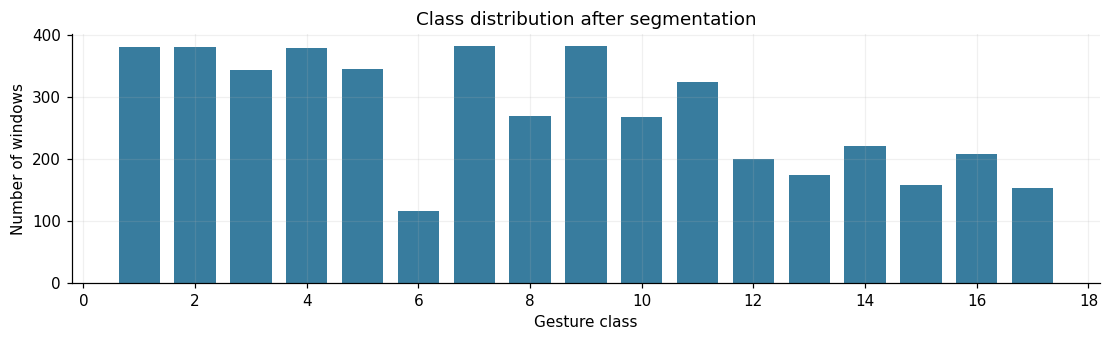

In [6]:
X, y, groups = make_windows(
    emg_filtered, stimulus, repetition,
    fs=FS, window_ms=WINDOW_MS, stride_ms=STRIDE_MS, include_rest=False
)
assert X.shape[1] == 120 and np.isfinite(X).all()
assert len(np.unique(y)) == 17
print(f'Extracted windows: {X.shape[0]:,}')
print(f'Features per window: {X.shape[1]}')
print(f'Gesture classes: {len(np.unique(y))}')
class_counts = pd.Series(y).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10.2, 3.2))
ax.bar(class_counts.index, class_counts.values, color='#387C9E', width=.74)
ax.set(xlabel='Gesture class', ylabel='Number of windows', title='Class distribution after segmentation')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout(); plt.show()

## 4. Classification and evaluation protocol

**Repetitions 2 and 5** are reserved for testing; all remaining repetitions are used for training. This prevents the same movement repetition, and its overlapping signal windows, from contributing to both partitions.

Four classifiers are trained: RBF support vector machine (SVM), linear discriminant analysis (LDA), K-nearest neighbors (KNN, `k=5`), and random forest (`100` trees). A `StandardScaler` is fitted only on the training partition for SVM, LDA, and KNN; the random forest receives unscaled features. No hyperparameter search or tuning against test data is performed.

In [7]:
def train_evaluate(features, labels, repetitions, test_repetitions=(2, 5)):
    """Use disjoint repetition IDs for train/test, ensuring training and testing use disjoint source repetitions."""
    test = np.isin(repetitions, list(test_repetitions))
    train = ~test
    if not train.any() or not test.any():
        raise ValueError("Training or test partition is empty; check --test-reps")
    if set(repetitions[train]) & set(repetitions[test]):
        raise AssertionError("Train/test repetition overlap")
    train_labels = set(labels[train])
    test_labels = set(labels[test])
    if train_labels != test_labels:
        raise ValueError(f"Classes missing in train/test: {train_labels ^ test_labels}")
    models = {
        "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1., gamma="scale")),
        "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
        "KNN-5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    }
    results = {}
    for name, model in models.items():
        model.fit(features[train], labels[train])
        predictions = model.predict(features[test])
        results[name] = {
            "accuracy": accuracy_score(labels[test], predictions),
            "balanced_accuracy": balanced_accuracy_score(labels[test], predictions),
            "macro_f1": f1_score(labels[test], predictions, average="macro", zero_division=0),
            "model": model,
            "predictions": predictions,
        }
    return results, labels[test], (int(train.sum()), int(test.sum()))

In [8]:
test_mask = np.isin(groups, TEST_REPETITIONS)
assert len(set(groups[test_mask]).intersection(set(groups[~test_mask]))) == 0
assert not np.any(np.isin(groups[~test_mask], TEST_REPETITIONS))
results, y_test, (n_train, n_test) = train_evaluate(X, y, groups, TEST_REPETITIONS)

metrics = pd.DataFrame([
    {'Classifier': name, 'Accuracy (%)': 100*r['accuracy'],
     'Balanced accuracy (%)': 100*r['balanced_accuracy'],
     'Macro-F1 (%)': 100*r['macro_f1']}
    for name, r in results.items()
]).sort_values('Accuracy (%)', ascending=False, ignore_index=True)
print(f'Training windows: {n_train:,} | Test windows: {n_test:,}')
print(f'Test repetition IDs: {TEST_REPETITIONS}')
print(metrics.to_string(index=False, float_format=lambda x: f'{x:.2f}'))
assert n_train == 3183 and n_test == 1515
assert np.isclose(results['RandomForest']['accuracy'], 0.7425742574257426)

Training windows: 3,183 | Test windows: 1,515
Test repetition IDs: (2, 5)
  Classifier  Accuracy (%)  Balanced accuracy (%)  Macro-F1 (%)
RandomForest         74.26                  75.09         75.17
     SVM-RBF         67.72                  70.31         70.29
         LDA         62.77                  65.69         66.04
       KNN-5         61.45                  64.65         65.49


## 5. Results

Accuracy measures the overall proportion of correctly predicted windows. Balanced accuracy averages recall across the 17 gestures; macro-F1 assigns equal weight to each gesture's F1 score. Confusion matrices below use the same held-out test set for every classifier.

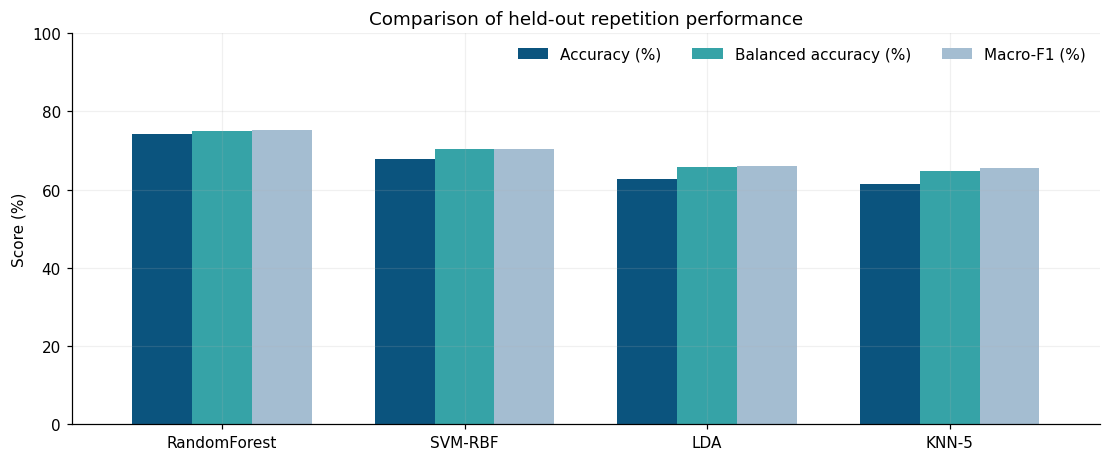

In [9]:
ax = metrics.set_index('Classifier')[['Accuracy (%)', 'Balanced accuracy (%)', 'Macro-F1 (%)']].plot(
    kind='bar', figsize=(10.2, 4.3), rot=0, width=.74,
    color=['#0B547E', '#36A3A7', '#A4BDD1']
)
ax.set(ylabel='Score (%)', title='Comparison of held-out repetition performance', ylim=(0, 100), xlabel='')
ax.legend(frameon=False, ncol=3, loc='upper right')
fig = ax.get_figure(); fig.tight_layout(); plt.show()

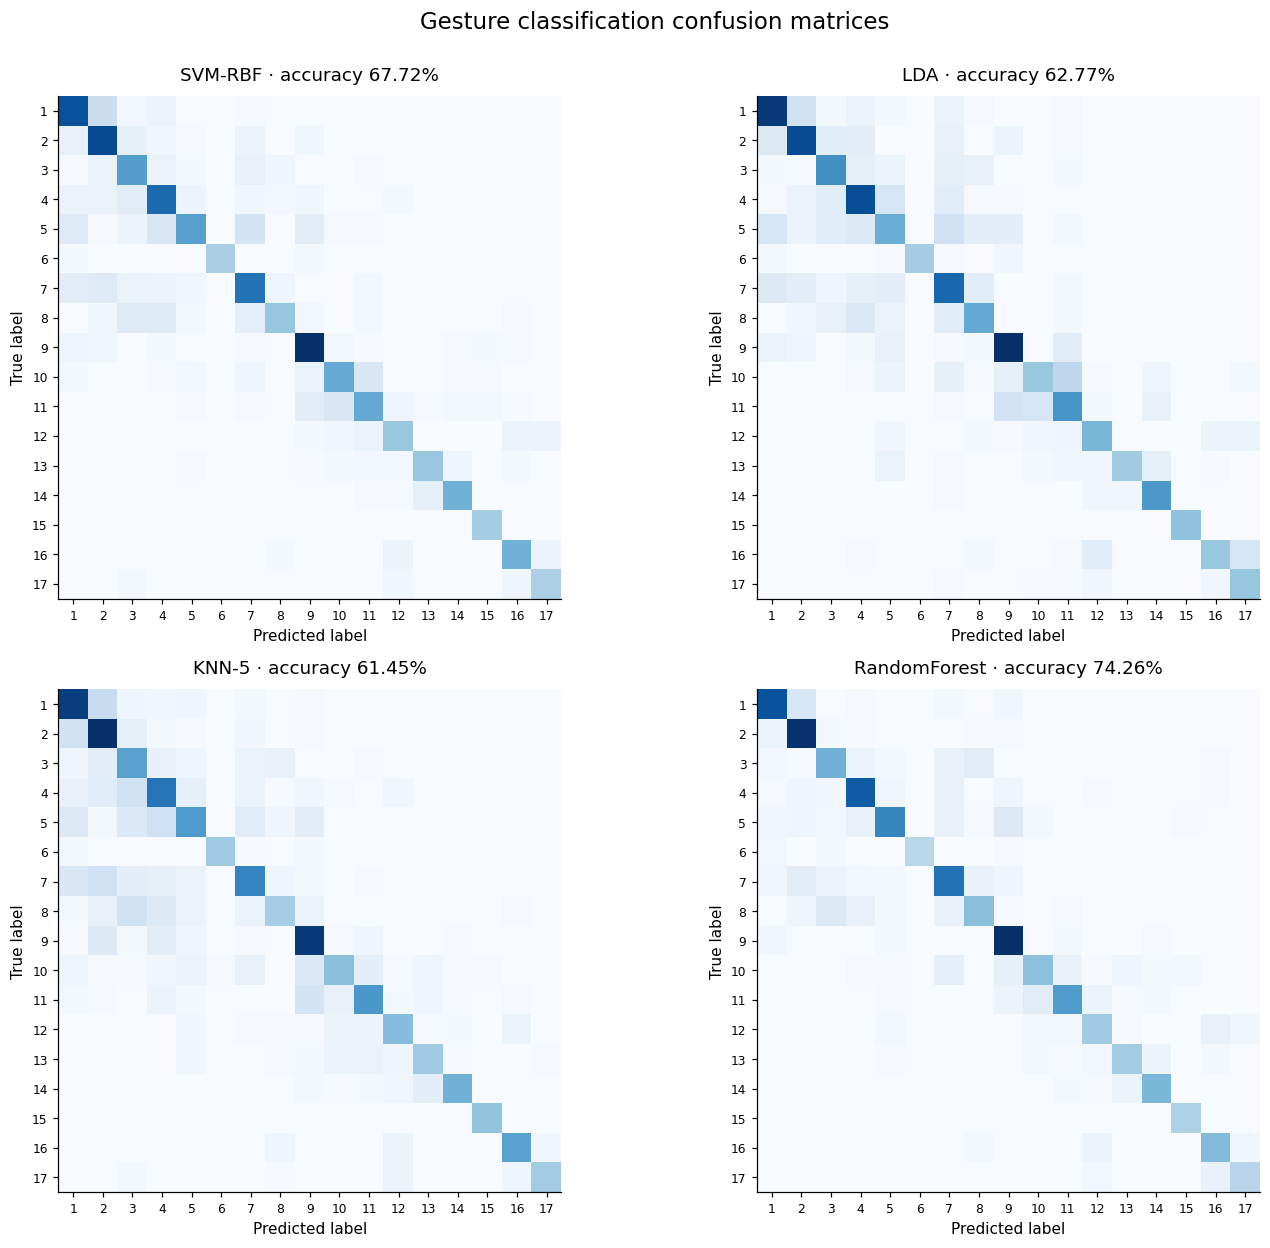

In [10]:
labels = np.unique(y_test)
fig, axes = plt.subplots(2, 2, figsize=(13.2, 11.3))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    cm = confusion_matrix(y_test, r['predictions'], labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap='Blues', colorbar=False, include_values=False
    )
    ax.grid(False)
    ax.set_title(f'{name} · accuracy {100*r["accuracy"]:.2f}%', fontsize=12, pad=10)
    ax.tick_params(axis='both', labelsize=8)
fig.suptitle('Gesture classification confusion matrices', y=1.0, fontsize=15)
fig.tight_layout(); plt.show()

### 5.1 Class-wise analysis of the best-performing model

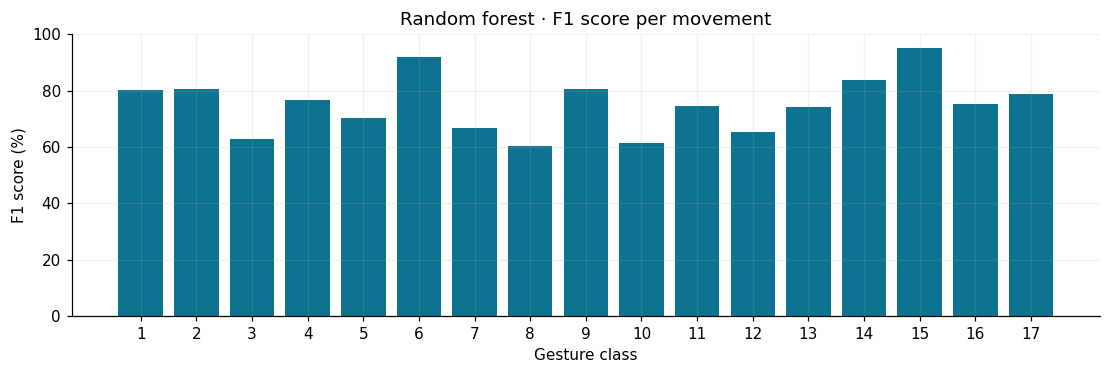

Highest off-diagonal confusion counts (count, true class, predicted class):
 18  |   1 →  2
 15  |   8 →  3
 15  |   5 →  9
 13  |  11 → 10
 13  |   3 →  8


In [11]:
rf_prediction = results['RandomForest']['predictions']
report = classification_report(y_test, rf_prediction, labels=labels, output_dict=True, zero_division=0)
class_f1 = np.array([report[str(label)]['f1-score'] for label in labels])
fig, ax = plt.subplots(figsize=(10.2, 3.5))
ax.bar(labels, class_f1 * 100, color='#0E7391')
ax.set(xlabel='Gesture class', ylabel='F1 score (%)', ylim=(0, 100),
       title='Random forest · F1 score per movement')
ax.set_xticks(labels)
fig.tight_layout(); plt.show()

cm_rf = confusion_matrix(y_test, rf_prediction, labels=labels)
misclassified = cm_rf.copy(); np.fill_diagonal(misclassified, 0)
confusions=[]
for i,j in np.argwhere(misclassified > 0):
    confusions.append((int(misclassified[i,j]), int(labels[i]), int(labels[j])))
confusions.sort(reverse=True)
print('Highest off-diagonal confusion counts (count, true class, predicted class):')
for count, actual, predicted in confusions[:5]:
    print(f'{count:>3}  |  {actual:>2} → {predicted:>2}')

### 5.2 Per-class summary (random forest)

Precision, recall, and F1 are reported for every movement category, together with the number of test windows.

In [12]:
class_scores = pd.DataFrame([{
    'Gesture': int(label),
    'Precision (%)': 100 * report[str(label)]['precision'],
    'Recall (%)': 100 * report[str(label)]['recall'],
    'F1 (%)': 100 * report[str(label)]['f1-score'],
    'Support': int(report[str(label)]['support']),
} for label in labels])
print(class_scores.to_string(index=False, float_format=lambda v: f'{v:.2f}'))

 Gesture  Precision (%)  Recall (%)  F1 (%)  Support
       1          80.31       80.31   80.31      127
       2          71.78       91.41   80.41      128
       3          64.04       61.96   62.98       92
       4          76.56       76.56   76.56      128
       5          81.44       61.72   70.22      128
       6         100.00       85.00   91.89       40
       7          64.71       68.75   66.67      128
       8          66.67       54.95   60.24       91
       9          71.08       92.91   80.55      127
      10          71.01       53.85   61.25       91
      11          80.23       69.70   74.59       99
      12          65.15       65.15   65.15       66
      13          76.36       72.41   74.34       58
      14          81.82       85.71   83.72       63
      15          90.48      100.00   95.00       38
      16          71.23       80.00   75.36       65
      17          81.40       76.09   78.65       46


## 6. Interpretation

The **random forest** achieved the highest held-out performance, with **74.26% accuracy**, **75.09% balanced accuracy**, and **75.17% macro-F1**. The SVM ranked second; LDA and KNN performed less well under the same feature set and evaluation protocol. The class-wise scores and confusion matrices show which gesture categories are most often confused.

The experiment evaluates separation between repetitions **within Subject 14**. A multi-subject study with participant-disjoint testing would be required to quantify cross-person generalization; that claim is not made here.